# Stop/Save Behavioral EDA — V3

This notebook profiles mature contacted users from the current P3 usage and revenue outputs. 
- Contacted **Not Gamers** define the behavioral reference and the main Saved-versus-voluntary-Stopped contrasts. 
- **Gamers** are then profiled against that same reference by repeat stop-save, paid-lower-rate, repeat-restart, restart-contract, and restart stop-save behavior.
- No Action users are retained only for population context. 
- Treatment drill-down and the restart revenue scenario are descriptive, not causal estimates.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.cloud import bigquery

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").exists()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.eda_helpers import (
    ID_COL,
    OUTCOME_COL,
    build_behavior_profiles,
    build_distribution_summary,
    build_outcome_contrasts,
    build_treatment_contrasts,
    fit_behavior_reference,
    plot_behavior_contrasts_boxplots,
    plot_metric_boxplot_views,
    plot_profile_or_contrast_heatmap,
)

In [2]:
PROJECT_ID = "gannett-datascience"
USAGE_TABLE = "gannett-datascience.test_results_zone.ss_test_P3_usages_features"
REVENUE_TABLE = "gannett-datascience.test_results_zone.ss_test_P3_revenue_analysis"

BEHAVIOR_METRICS = ["frequency", "breadth", "tenure", "tt_cost", "modelscore"]
CATEGORICAL_DIMENSIONS = [
    "rfv_bin",
    "favor_platforms",
    "is_T1T2",
    "is_selected_80Mkts",
    "market",
]
CORE_SEGMENT_FIELDS = [
    "contact_channels",
    "contact_timing",
    "cohort",
    "src_risk_tier",
]
MIN_PROFILE_USERS = 20
MIN_GAMER_PROFILE_USERS = 10
MIN_TREATMENT_USERS = 5
TOP_CONTRASTS = 8

OUTPUT_ROOT = PROJECT_ROOT / "src" / "notebooks"
CHART_DIR = OUTPUT_ROOT / "charts" / "eda_complete_v3"
TABLE_DIR = OUTPUT_ROOT / "tables" / "eda_complete_v3"
OVERVIEW_CHART_DIR = CHART_DIR / "overview"
PROFILE_CHART_DIR = CHART_DIR / "profiles"
CONTRAST_CHART_DIR = CHART_DIR / "contrasts"
REVENUE_CHART_DIR = CHART_DIR / "revenue"
for folder in [
    OVERVIEW_CHART_DIR, PROFILE_CHART_DIR, CONTRAST_CHART_DIR,
    REVENUE_CHART_DIR, TABLE_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

## 1. Load mature P3 usage data and repeat-restarter revenue

The maturity flag is supplied by P2. `session_per_day_in_90d` is intentionally not selected. Revenue is joined one-to-one from the original subscription in the usage table to `origin_id_subscrip` in P3 revenue.

In [ ]:
usage_fields = [
    ID_COL, "id_subscrip", "inference_date", "email_date",
    "is_two_payment_cycle_ago", "cohort", "Treatment",
    "contact_timing", "src_risk_tier",
    "Repeat_Restarts", "Repeat_StopSaves", "churn_code",
    *BEHAVIOR_METRICS, *CATEGORICAL_DIMENSIONS,
]
usage_query = f"""
SELECT {', '.join(usage_fields)}
, if(contains_substr(contact_channels, 'both'), 'Contacted both ways', contact_channels) as contact_channels
FROM `{USAGE_TABLE}`
WHERE is_two_payment_cycle_ago = 1
"""
revenue_query = f"""
SELECT
  origin_id_subscrip,
  actual_paid_invoice_value,
  expected_fixed_revenue,
  service_period_type,
  had_restart_stop_save
FROM `{REVENUE_TABLE}`
"""

client = bigquery.Client(project=PROJECT_ID)
usage = client.query(usage_query).to_dataframe(create_bqstorage_client=False)
revenue = client.query(revenue_query).to_dataframe(create_bqstorage_client=False)

if usage[ID_COL].isna().any() or usage[ID_COL].duplicated().any():
    raise ValueError("Mature P3 usage data must contain one non-missing row per billing account.")
if usage["id_subscrip"].isna().any() or usage["id_subscrip"].duplicated().any():
    raise ValueError("Mature P3 usage data must contain one non-missing row per subscription.")
if revenue["origin_id_subscrip"].isna().any() or revenue["origin_id_subscrip"].duplicated().any():
    raise ValueError("P3 revenue must contain one non-missing row per repeat-restart origin.")

df = usage.merge(
    revenue,
    how="left",
    left_on="id_subscrip",
    right_on="origin_id_subscrip",
    validate="one_to_one",
)
df[BEHAVIOR_METRICS] = df[BEHAVIOR_METRICS].astype("float64")
print(f"Loaded {len(df):,} mature accounts and {len(revenue):,} repeat-restart revenue rows.")

/Users/YKang1/PycharmProjects/stop_save_pChurn/.venv/lib/python3.13/site-packages/google/auth/_default.py:113: UserWarning: Your application has authenticated using end user credentials from Google Cloud SDK without a quota project. You might receive a "quota exceeded" or "API not enabled" error. See the following page for troubleshooting: https://cloud.google.com/docs/authentication/adc-troubleshooting/user-creds. 
  warnings.warn(_CLOUD_SDK_CREDENTIALS_WARNING)


Loaded 62,480 mature accounts and 656 repeat-restart revenue rows.


## 2. Define analysis populations

The analysis uses local boolean masks rather than adding aliases to the source dataframe. Contacted Not Gamers are the complete behavioral baseline. Readable outcome labels are added later only to the local baseline dataframe used by the plotting helpers.

In [7]:
PAID_LOWER_LABELS = {
    "seek offer 2+, pay lower than ss",
    "seek offer both channels, pay lower than ss",
}

contacted = df["contact_channels"].ne("No Action yet")
repeat_restarters = df["Repeat_Restarts"].ne("not repeat restarts")
repeat_stop_saves = df["Repeat_StopSaves"].ne("not repeate stop-saves")
paid_lower_repeat_stop_saves = df["Repeat_StopSaves"].isin(PAID_LOWER_LABELS)
gamers = repeat_restarters | repeat_stop_saves

In [ ]:
masks = {
    "All mature users": pd.Series(True, index=df.index),
    "No Action": ~contacted,
    "Contacted": contacted,
    "Contacted — Gamers": gamers,
    "Contacted — Not Gamers": contacted & ~gamers,
    "Not Gamers — Saved": ~gamers & df["churn_code"].eq(0),
    "Not Gamers — Voluntary Stopped": ~gamers & df["churn_code"].eq(1),
    "Gamers — Repeat stop-save": repeat_stop_saves,
    "Gamers — Repeat restarter": repeat_restarters,
    "Repeat stop-save — Paid lower": paid_lower_repeat_stop_saves,
    "Repeat stop-save — Did not pay lower": repeat_stop_saves & ~paid_lower_repeat_stop_saves,
}
population_counts = pd.DataFrame(
    [{"population": label, "accounts": int(mask.sum())} for label, mask in masks.items()]
)
population_counts["share_of_mature_pct"] = population_counts["accounts"] / len(df) * 100
population_counts["share_of_contacted_pct"] = np.nan
contacted_rows = ~population_counts["population"].isin(["All mature users", "No Action"])
population_counts.loc[contacted_rows, "share_of_contacted_pct"] = (
    population_counts.loc[contacted_rows, "accounts"] / contacted.sum() * 100
)
population_counts.to_csv(TABLE_DIR / "population_counts.csv", index=False)
display(population_counts)

,population,accounts,share_of_mature_pct,share_of_contacted_pct
0,All mature users,62480,100.00,NaN
1,No Action,50301,80.51,NaN
2,Contacted,12179,19.49,100.00
3,Contacted — Gamers,2548,4.08,20.92
4,Contacted — Not Gamers,59932,95.92,492.09
5,Not Gamers — Saved,2967,4.75,24.36
6,Not Gamers — Voluntary Stopped,6664,10.67,54.72
7,Gamers — Repeat stop-save,1991,3.19,16.35
8,Gamers — Repeat restarter,557,0.89,4.57
9,Repeat stop-save — Paid lower,327,0.52,2.68


In [11]:
quality_populations = {
    "All mature users": df,
    "Contacted": df.loc[contacted],
    "Not Gamers": df.loc[~gamers],
    "Gamers": df.loc[gamers],
}
distribution_summary = pd.concat(
    [
        build_distribution_summary(frame, BEHAVIOR_METRICS).assign(population=name)
        for name, frame in quality_populations.items()
    ],
    ignore_index=True,
)
distribution_summary.insert(0, "population", distribution_summary.pop("population"))
distribution_summary.to_csv(TABLE_DIR / "distribution_summary.csv", index=False)
display(distribution_summary)

,population,field,row_count,non_null_count,null_count,null_pct,zero_count,negative_count,min,max,mean,median,std,p01,p05,p10,p25,p50,p75,p90,p95,p99,iqr,lower_bound,upper_bound,outlier_count,outlier_pct
0,All mature users,frequency,62480,62442,38,0.06,12723,0,0.00,91.00,36.82,26.00,34.73,0.00,0.00,0.00,2.00,26.00,74.00,89.00,91.00,91.00,72.00,-106.00,182.00,0,0.00
1,All mature users,breadth,62480,62442,38,0.06,19499,0,0.00,24.00,4.05,3.00,4.13,0.00,0.00,0.00,0.00,3.00,7.00,10.00,12.00,15.00,7.00,-10.50,17.50,117,0.19
2,All mature users,tenure,62480,62442,38,0.06,0,0,201.00,"46,227.00","1,368.65","1,330.00","1,054.44",325.00,346.00,356.00,783.00,"1,330.00","1,678.00","2,118.00","2,701.00","4,368.95",895.00,-559.50,"3,020.50",1999,3.20
3,All mature users,tt_cost,62480,62442,38,0.06,98,0,0.00,"30,802.59",614.29,522.81,559.76,59.71,114.94,160.18,269.63,522.81,813.59,"1,130.10","1,280.72","2,308.30",543.97,-546.32,"1,629.54",1677,2.69
4,All mature users,modelscore,62480,62377,103,0.16,12640,0,0.00,125.00,24.19,6.00,34.55,0.00,0.00,0.00,1.00,6.00,36.00,80.00,100.00,125.00,35.00,-51.50,88.50,5349,8.58
5,Contacted,frequency,12179,12173,6,0.05,1817,0,0.00,91.00,41.05,35.00,34.58,0.00,0.00,0.00,5.00,35.00,78.00,90.00,91.00,91.00,73.00,-104.50,187.50,0,0.00
6,Contacted,breadth,12179,12173,6,0.05,2975,0,0.00,20.00,4.63,4.00,4.20,0.00,0.00,0.00,1.00,4.00,8.00,11.00,12.00,15.00,7.00,-9.50,18.50,11,0.09
7,Contacted,tenure,12179,12173,6,0.05,0,0,201.00,"27,951.00","1,476.69","1,395.00","1,100.04",326.00,354.00,360.00,906.00,"1,395.00","1,716.00","2,454.00","2,928.00","4,746.52",810.00,-309.00,"2,931.00",601,4.94
8,Contacted,tt_cost,12179,12173,6,0.05,3,0,0.00,"13,966.18",529.66,444.78,484.58,59.21,114.44,131.70,238.36,444.78,679.43,984.84,"1,172.08","2,083.70",441.07,-423.25,"1,341.04",424,3.48
9,Contacted,modelscore,12179,12159,20,0.16,1801,0,0.00,125.00,24.01,6.00,33.77,0.00,0.00,0.00,2.00,6.00,36.00,80.00,100.00,125.00,34.00,-49.00,87.00,987,8.12


## 3. Not Gamer behavioral reference and main Saved-versus-voluntary-Stopped contrasts

The common reference is fitted once on contacted Not Gamers: clip at the 1st and 99th percentiles, center on the population median, and scale by the population IQR. In this section, `Stopped` means voluntary stop (`churn_code=1`) only.

,metric,p01,median,iqr,p99
0,frequency,0.00,24.00,70.00,91.00
1,breadth,0.00,3.00,7.00,15.00
2,tenure,325.00,"1,328.00",893.00,"4,326.00"
3,tt_cost,59.71,527.47,545.06,"2,310.48"
4,modelscore,0.00,6.00,35.00,125.00


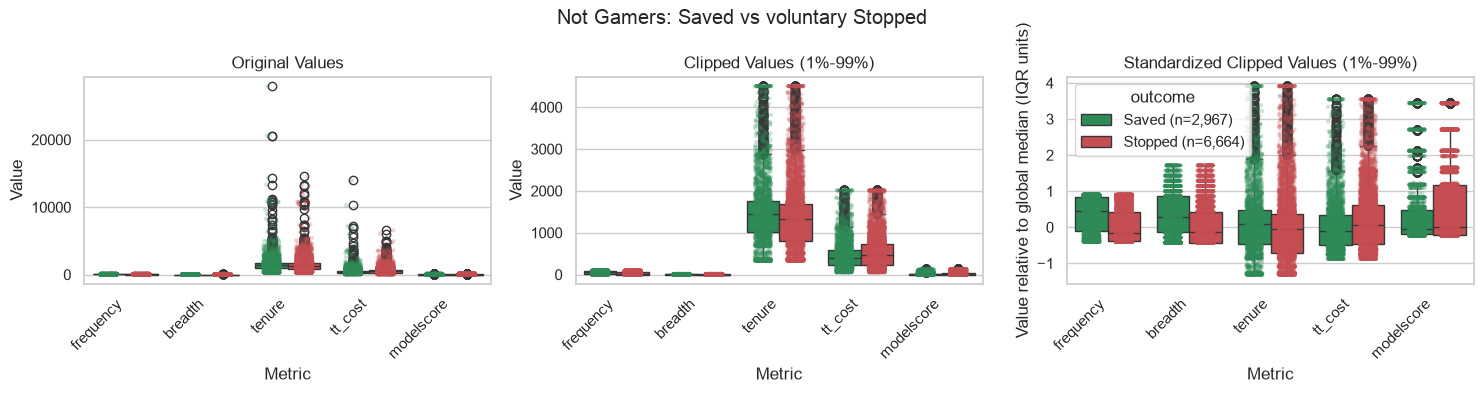

In [13]:
baseline = df.loc[~gamers].copy()
baseline[OUTCOME_COL] = baseline["churn_code"].map({0: "Saved", 1: "Stopped"})

behavior_reference = fit_behavior_reference(baseline, BEHAVIOR_METRICS)
reference_table = pd.DataFrame(
    {
        "p01": behavior_reference["lower_bounds"],
        "median": behavior_reference["centers"],
        "iqr": behavior_reference["spreads"],
        "p99": behavior_reference["upper_bounds"],
    }
).rename_axis("metric").reset_index()
reference_table.to_csv(TABLE_DIR / "primary_behavior_reference.csv", index=False)
display(reference_table)

_ = plot_metric_boxplot_views(
    baseline,
    metrics=BEHAVIOR_METRICS,
    group_col=OUTCOME_COL,
    group_order=["Saved", "Stopped"],
    chart_title="Not Gamers: Saved vs voluntary Stopped",
    chart_folder=OVERVIEW_CHART_DIR,
    file_name="not_gamer_saved_vs_stopped.png",
    show=True,
)

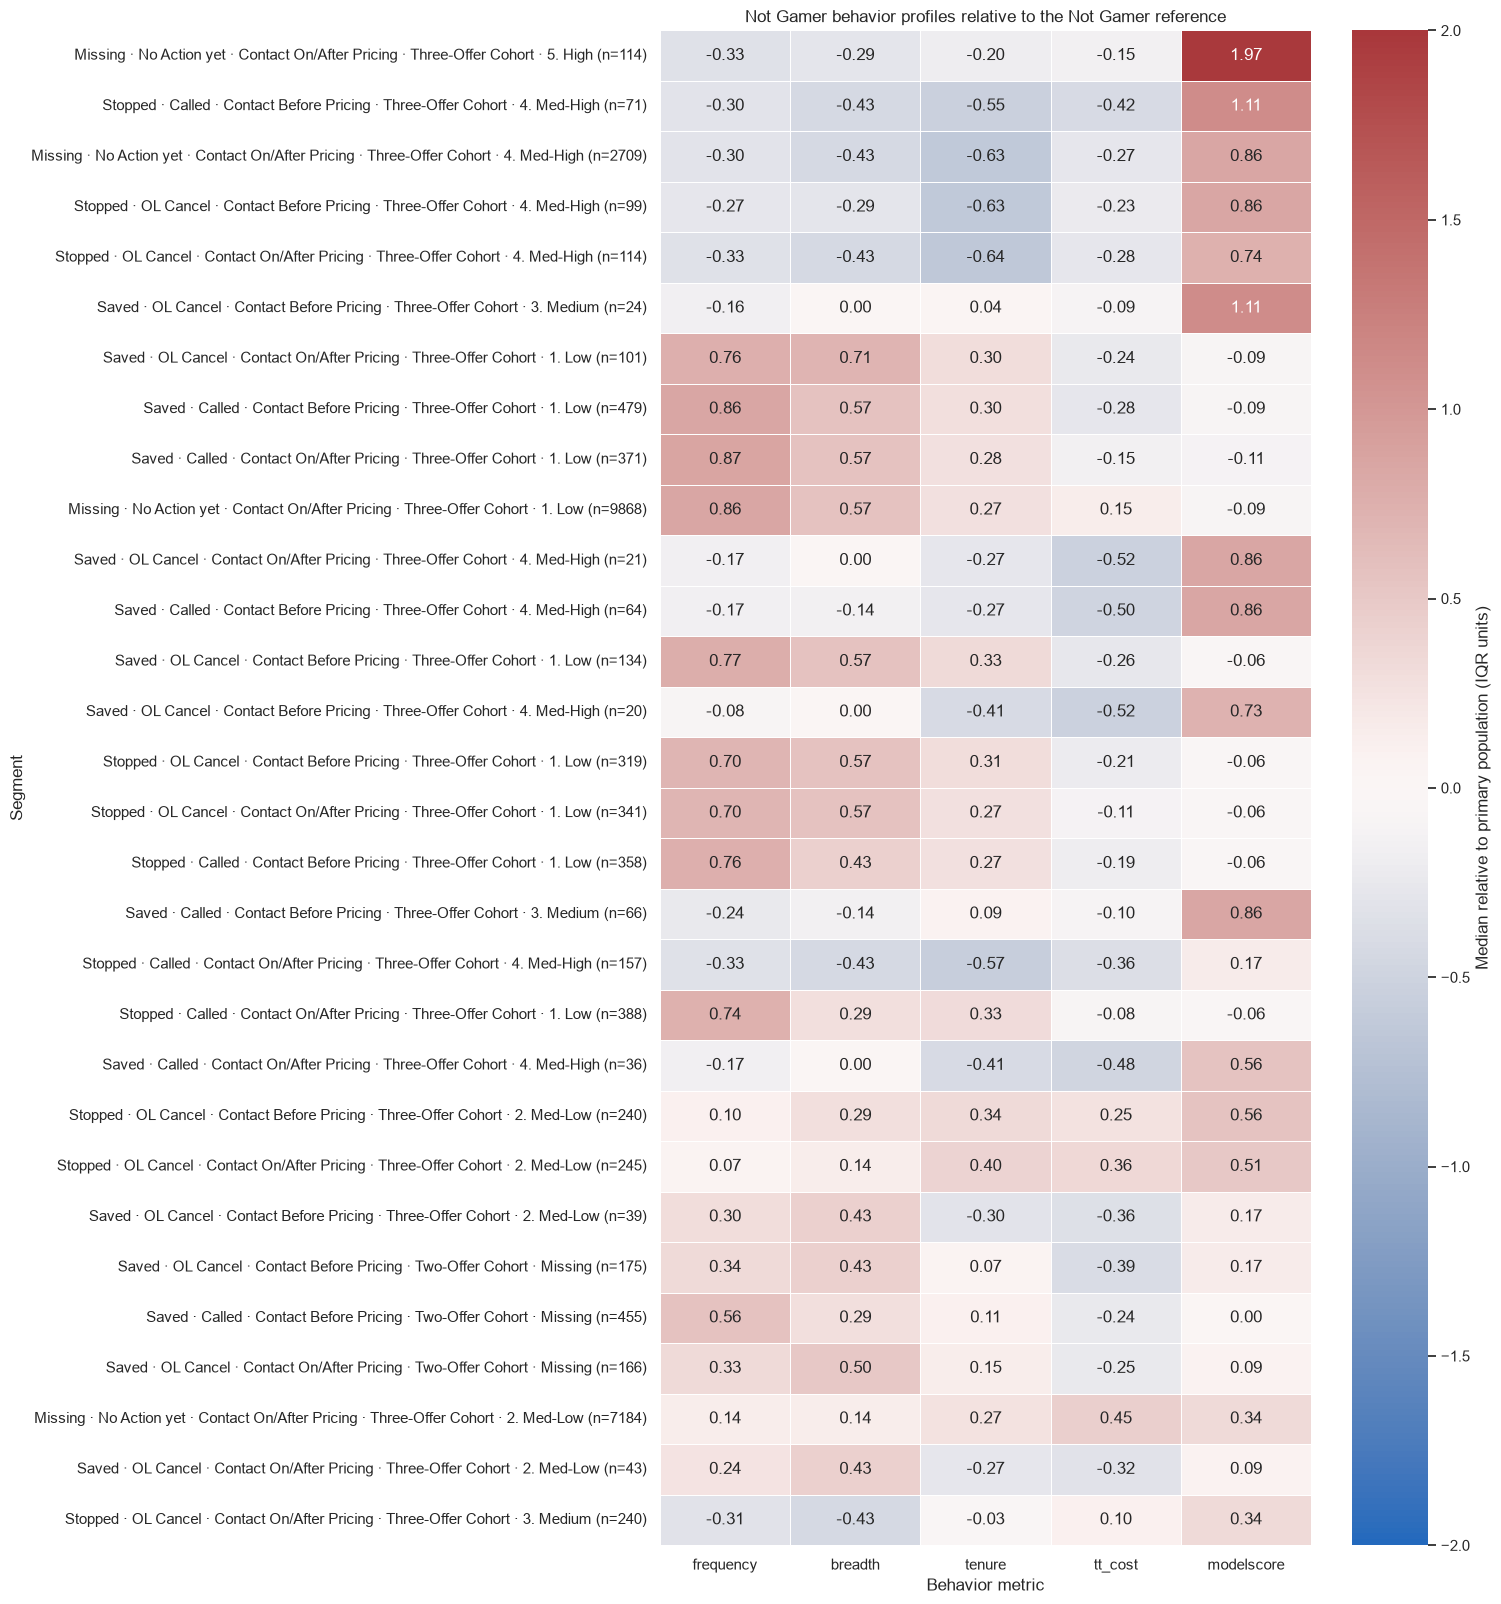

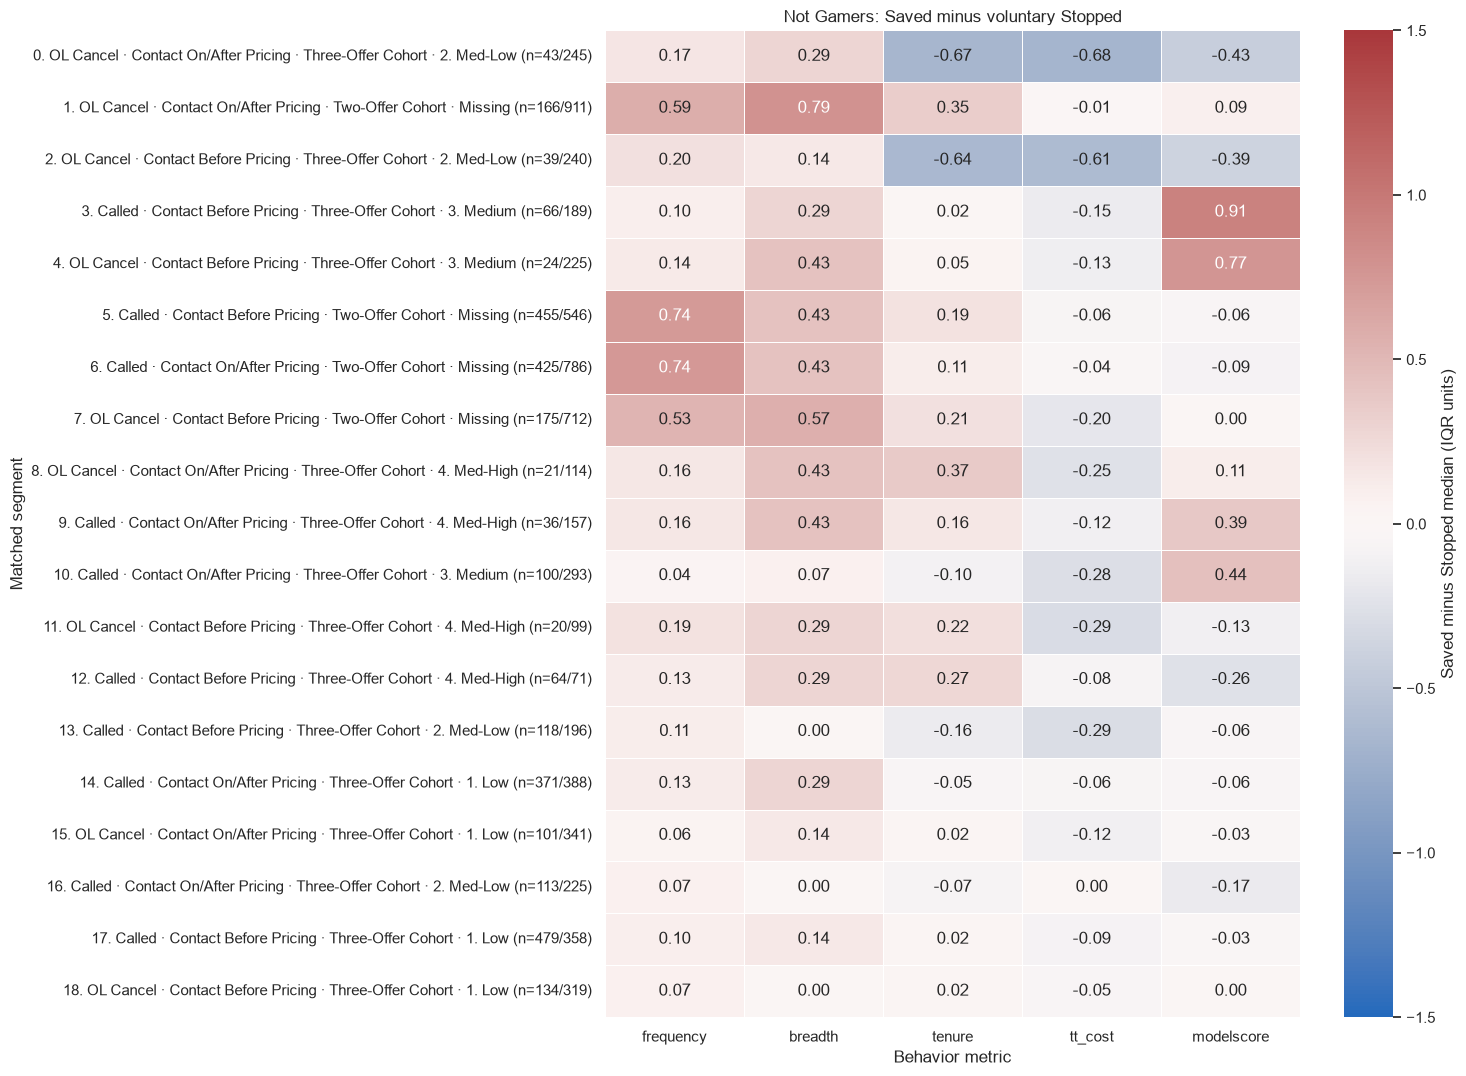

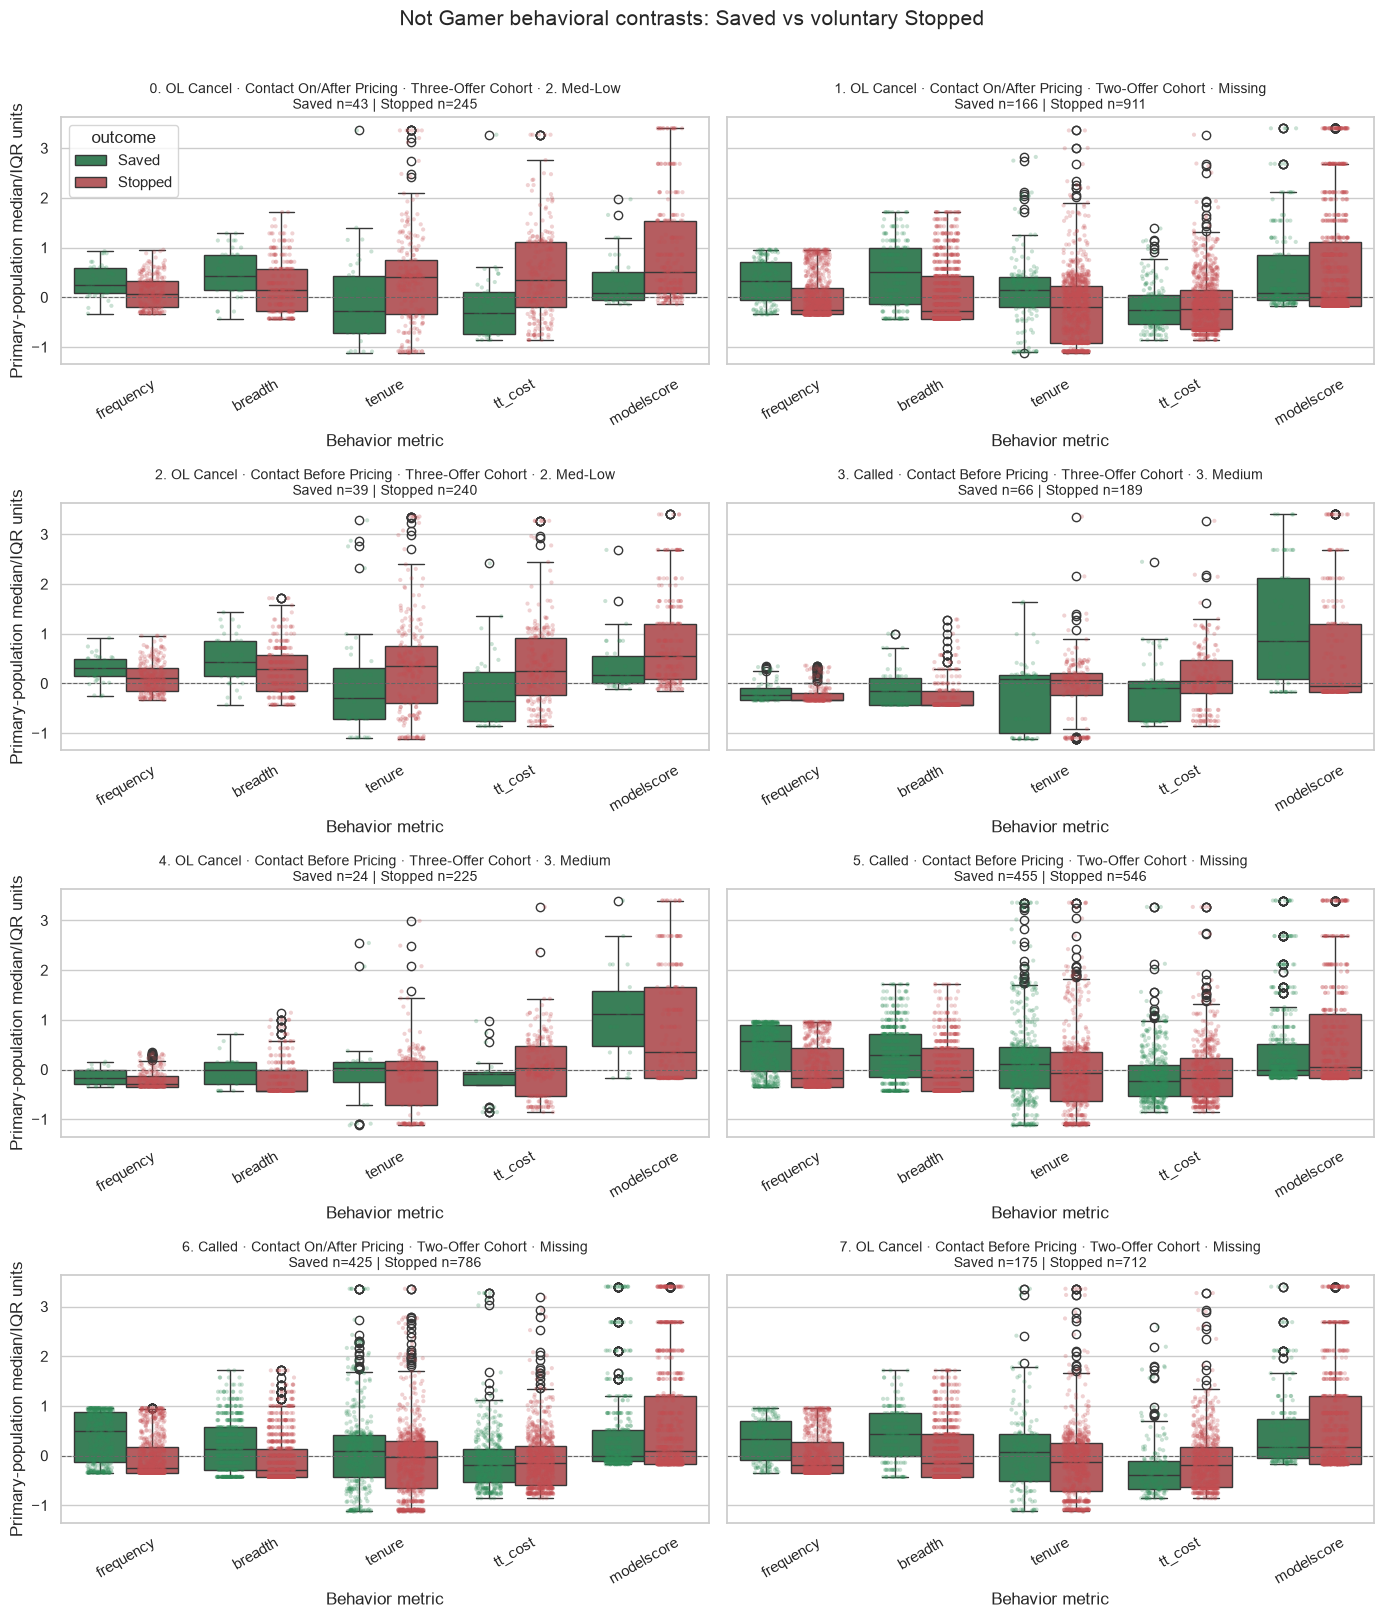

,segment_rank,contact_channels,contact_timing,cohort,src_risk_tier,segment_label,n__saved,n__stopped,median_saved__frequency,median_saved__breadth,median_saved__tenure,median_saved__tt_cost,median_saved__modelscore,median_stopped__frequency,median_stopped__breadth,median_stopped__tenure,median_stopped__tt_cost,median_stopped__modelscore,delta__frequency,delta__breadth,delta__tenure,delta__tt_cost,delta__modelscore,total_users,observed_saved_share,contrast_magnitude,dominant_metric,dominant_outcome
0,0,OL Cancel,Contact On/After Pricing,Three-Offer Cohort,2. Med-Low,OL Cancel · Contact On/After Pricing · Three-O...,43,245,41.00,6.00,"1,090.00",352.31,9.00,29.00,4.00,"1,684.00",721.07,24.00,0.17,0.29,-0.67,-0.68,-0.43,288,0.15,1.09,tt_cost,Stopped
1,1,OL Cancel,Contact On/After Pricing,Two-Offer Cohort,NaN,OL Cancel · Contact On/After Pricing · Two-Off...,166,911,47.00,6.50,"1,462.50",392.29,9.00,6.00,1.00,"1,151.50",400.12,6.00,0.59,0.79,0.35,-0.01,0.09,1077,0.15,1.04,breadth,Saved
2,2,OL Cancel,Contact Before Pricing,Three-Offer Cohort,2. Med-Low,OL Cancel · Contact Before Pricing · Three-Off...,39,240,45.00,6.00,"1,058.00",333.67,12.00,31.00,5.00,"1,633.50",666.33,25.50,0.20,0.14,-0.64,-0.61,-0.39,279,0.14,1.00,tenure,Stopped
3,3,Called,Contact Before Pricing,Three-Offer Cohort,3. Medium,Called · Contact Before Pricing · Three-Offer ...,66,189,7.00,2.00,"1,406.50",475.69,36.00,0.00,0.00,"1,389.00",558.75,4.00,0.10,0.29,0.02,-0.15,0.91,255,0.26,0.98,modelscore,Saved
4,4,OL Cancel,Contact Before Pricing,Three-Offer Cohort,3. Medium,OL Cancel · Contact Before Pricing · Three-Off...,24,225,12.50,3.00,"1,361.00",475.93,45.00,3.00,0.00,"1,319.00",549.12,18.00,0.14,0.43,0.05,-0.13,0.77,249,0.10,0.90,modelscore,Saved
5,5,Called,Contact Before Pricing,Two-Offer Cohort,NaN,Called · Contact Before Pricing · Two-Offer Co...,455,546,63.50,5.00,"1,425.50",398.22,6.00,12.00,2.00,"1,257.00",431.01,8.00,0.74,0.43,0.19,-0.06,-0.06,1001,0.45,0.88,frequency,Saved
6,6,Called,Contact On/After Pricing,Two-Offer Cohort,NaN,Called · Contact On/After Pricing · Two-Offer ...,425,786,58.00,4.00,"1,402.50",423.85,6.00,6.00,1.00,"1,300.00",444.22,9.00,0.74,0.43,0.11,-0.04,-0.09,1211,0.35,0.87,frequency,Saved
7,7,OL Cancel,Contact Before Pricing,Two-Offer Cohort,NaN,OL Cancel · Contact Before Pricing · Two-Offer...,175,712,48.00,6.00,"1,393.00",312.54,12.00,11.00,2.00,"1,209.00",421.74,12.00,0.53,0.57,0.21,-0.20,0.00,887,0.20,0.83,breadth,Saved


In [14]:
behavior_profiles = build_behavior_profiles(
    baseline,
    metrics=BEHAVIOR_METRICS,
    segment_fields=[OUTCOME_COL, *CORE_SEGMENT_FIELDS],
    reference=behavior_reference,
    min_n=MIN_PROFILE_USERS,
)
behavior_profiles.to_csv(TABLE_DIR / "not_gamer_behavior_profiles.csv", index=False)
_ = plot_profile_or_contrast_heatmap(
    behavior_profiles,
    metrics=BEHAVIOR_METRICS,
    score_type="profile",
    max_rows=30,
    title="Not Gamer behavior profiles relative to the Not Gamer reference",
    chart_folder=PROFILE_CHART_DIR,
    file_name="not_gamer_behavior_profiles.png",
    show=True,
)

outcome_contrasts = build_outcome_contrasts(
    behavior_profiles,
    metrics=BEHAVIOR_METRICS,
    segment_fields=CORE_SEGMENT_FIELDS,
)
outcome_contrasts.to_csv(TABLE_DIR / "not_gamer_saved_minus_stopped_contrasts.csv", index=False)
_ = plot_profile_or_contrast_heatmap(
    outcome_contrasts,
    metrics=BEHAVIOR_METRICS,
    score_type="contrast",
    max_rows=20,
    color_limit=1.5,
    title="Not Gamers: Saved minus voluntary Stopped",
    chart_folder=CONTRAST_CHART_DIR,
    file_name="not_gamer_saved_minus_stopped_contrasts.png",
    show=True,
)
_ = plot_behavior_contrasts_boxplots(
    baseline,
    outcome_contrasts,
    metrics=BEHAVIOR_METRICS,
    segment_fields=CORE_SEGMENT_FIELDS,
    reference=behavior_reference,
    top_n=TOP_CONTRASTS,
    chart_folder=CONTRAST_CHART_DIR,
    file_name="not_gamer_top_behavior_contrasts.png",
    title="Not Gamer behavioral contrasts: Saved vs voluntary Stopped",
    show=True,
)
display(outcome_contrasts.head(TOP_CONTRASTS))

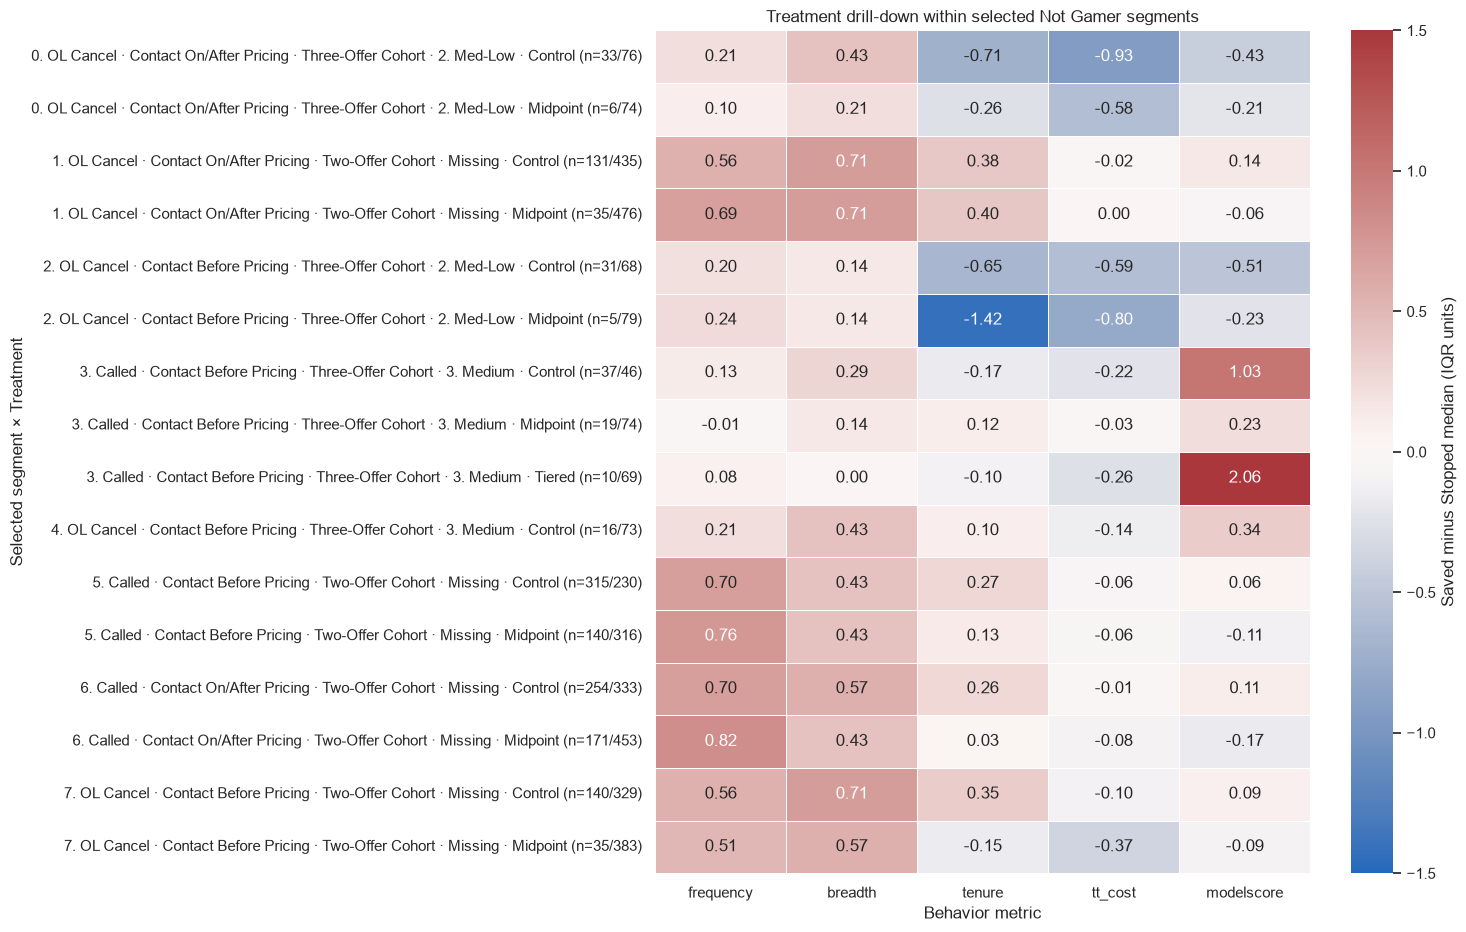

,segment_rank,segment_label,contact_channels,contact_timing,cohort,src_risk_tier,Treatment,n__saved,n__stopped,total_users,observed_saved_share,supported,median_saved__frequency,median_saved__breadth,median_saved__tenure,median_saved__tt_cost,median_saved__modelscore,median_stopped__frequency,median_stopped__breadth,median_stopped__tenure,median_stopped__tt_cost,median_stopped__modelscore,delta__frequency,delta__breadth,delta__tenure,delta__tt_cost,delta__modelscore,contrast_magnitude,dominant_metric
0,0,OL Cancel · Contact On/After Pricing · Three-O...,OL Cancel,Contact On/After Pricing,Three-Offer Cohort,2. Med-Low,Control,33,76,109,0.30,True,41.00,7.00,"1,090.00",360.97,9.00,26.00,4.00,"1,724.00",869.92,24.00,0.21,0.43,-0.71,-0.93,-0.43,1.34,tt_cost
1,0,OL Cancel · Contact On/After Pricing · Three-O...,OL Cancel,Contact On/After Pricing,Three-Offer Cohort,2. Med-Low,Midpoint,6,74,80,0.07,True,40.50,5.50,"1,223.50",332.31,10.50,33.50,4.00,"1,454.00",646.17,18.00,0.10,0.21,-0.26,-0.58,-0.21,0.71,tt_cost
2,0,OL Cancel · Contact On/After Pricing · Three-O...,OL Cancel,Contact On/After Pricing,Three-Offer Cohort,2. Med-Low,Tiered,4,95,99,0.04,False,44.50,2.50,907.50,150.95,26.00,29.00,3.00,"1,684.00",648.40,27.00,NaN,NaN,NaN,NaN,NaN,NaN,None
3,1,OL Cancel · Contact On/After Pricing · Two-Off...,OL Cancel,Contact On/After Pricing,Two-Offer Cohort,NaN,Control,131,435,566,0.23,True,43.00,6.00,"1,454.00",392.27,9.00,4.00,1.00,"1,118.00",402.93,4.00,0.56,0.71,0.38,-0.02,0.14,0.99,breadth
4,1,OL Cancel · Contact On/After Pricing · Two-Off...,OL Cancel,Contact On/After Pricing,Two-Offer Cohort,NaN,Midpoint,35,476,511,0.07,True,58.00,7.00,"1,537.00",397.90,6.00,10.00,2.00,"1,182.50",397.45,8.00,0.69,0.71,0.40,0.00,-0.06,1.07,breadth
5,1,OL Cancel · Contact On/After Pricing · Two-Off...,OL Cancel,Contact On/After Pricing,Two-Offer Cohort,NaN,Tiered,0,0,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
6,2,OL Cancel · Contact Before Pricing · Three-Off...,OL Cancel,Contact Before Pricing,Three-Offer Cohort,2. Med-Low,Control,31,68,99,0.31,True,45.00,6.00,"1,115.00",361.97,9.00,31.00,5.00,"1,692.50",681.32,27.00,0.20,0.14,-0.65,-0.59,-0.51,1.04,tenure
7,2,OL Cancel · Contact Before Pricing · Three-Off...,OL Cancel,Contact Before Pricing,Three-Offer Cohort,2. Med-Low,Midpoint,5,79,84,0.06,True,49.00,6.00,359.00,236.55,16.00,32.00,5.00,"1,628.00",670.24,24.00,0.24,0.14,-1.42,-0.80,-0.23,1.67,tenure
8,2,OL Cancel · Contact Before Pricing · Three-Off...,OL Cancel,Contact Before Pricing,Three-Offer Cohort,2. Med-Low,Tiered,3,93,96,0.03,False,37.00,4.00,692.00,115.10,18.00,29.00,4.00,"1,634.00",635.70,24.00,NaN,NaN,NaN,NaN,NaN,NaN,None
9,3,Called · Contact Before Pricing · Three-Offer ...,Called,Contact Before Pricing,Three-Offer Cohort,3. Medium,Control,37,46,83,0.45,True,9.00,2.00,"1,272.00",472.53,36.00,0.00,0.00,"1,420.50",594.17,0.00,0.13,0.29,-0.17,-0.22,1.03,1.11,modelscore


In [15]:
treatment_contrasts = build_treatment_contrasts(
    baseline,
    outcome_contrasts,
    metrics=BEHAVIOR_METRICS,
    segment_fields=CORE_SEGMENT_FIELDS,
    reference=behavior_reference,
    top_n=TOP_CONTRASTS,
    min_n=MIN_TREATMENT_USERS,
)
treatment_contrasts.to_csv(TABLE_DIR / "not_gamer_treatment_contrasts.csv", index=False)
supported_treatment = treatment_contrasts[treatment_contrasts["supported"]].copy()
_ = plot_profile_or_contrast_heatmap(
    supported_treatment,
    metrics=BEHAVIOR_METRICS,
    score_type="contrast",
    max_rows=30,
    color_limit=1.5,
    title="Treatment drill-down within selected Not Gamer segments",
    chart_folder=CONTRAST_CHART_DIR,
    file_name="not_gamer_treatment_contrasts.png",
    show=True,
)
display(treatment_contrasts.head(12))

## 4. Categorical behavior dimensions

RFV, platform, market tier, market flags, and market are analyzed one dimension at a time to avoid a sparse Cartesian segmentation. Differences are percentage-point differences in category shares.

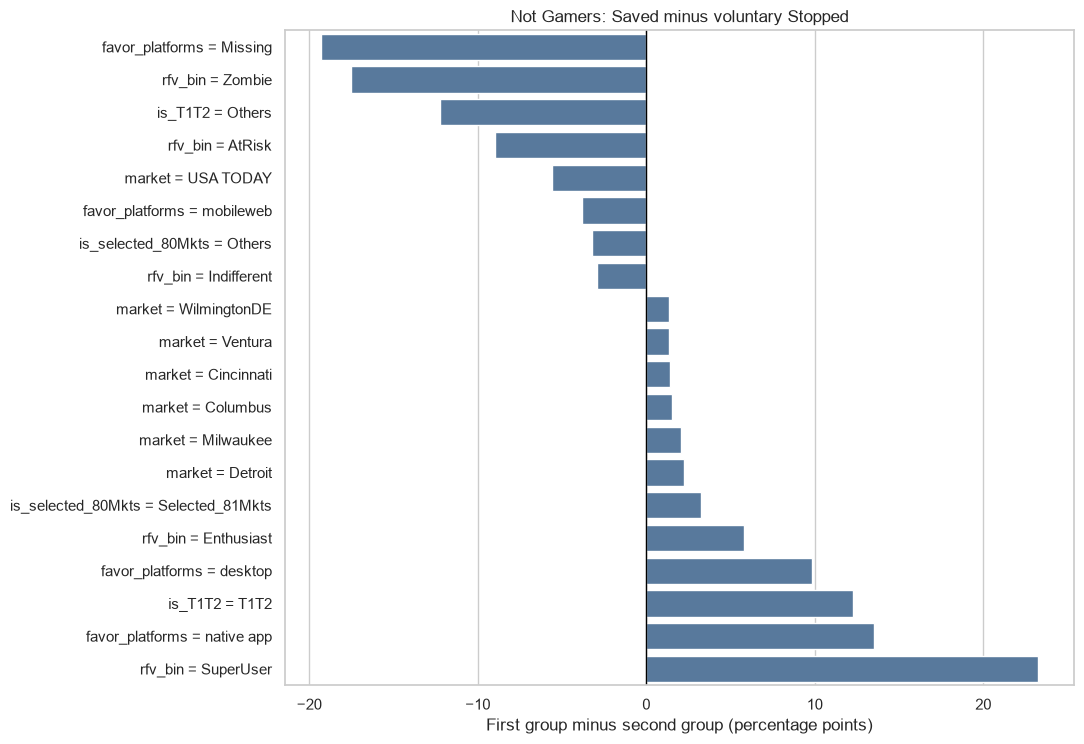

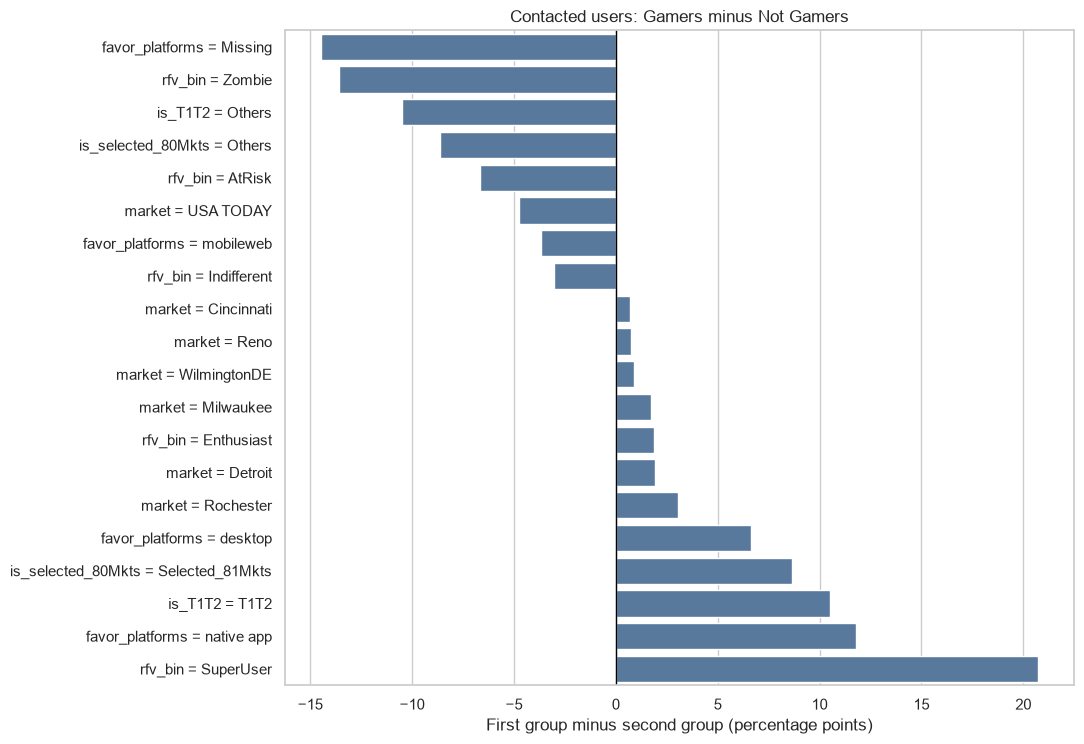

,comparison,dimension,dimension_value,category_n,first_group,second_group,first_share_pct,second_share_pct,share_difference_pp
4,Not Gamers: Saved minus voluntary Stopped,rfv_bin,SuperUser,3027,Saved,Stopped,47.52,24.26,23.26
120,Contacted users: Gamers minus Not Gamers,rfv_bin,SuperUser,4356,Gamers,Not Gamers,52.16,31.43,20.73
6,Not Gamers: Saved minus voluntary Stopped,favor_platforms,Missing,1942,Saved,Stopped,6.81,26.11,-19.30
5,Not Gamers: Saved minus voluntary Stopped,rfv_bin,Zombie,1698,Saved,Stopped,5.49,23.03,-17.54
122,Contacted users: Gamers minus Not Gamers,favor_platforms,Missing,2087,Gamers,Not Gamers,5.69,20.16,-14.47
121,Contacted users: Gamers minus Not Gamers,rfv_bin,Zombie,1801,Gamers,Not Gamers,4.04,17.63,-13.59
12,Not Gamers: Saved minus voluntary Stopped,favor_platforms,native app,3486,Saved,Stopped,45.53,32.04,13.50
14,Not Gamers: Saved minus voluntary Stopped,is_T1T2,T1T2,4721,Saved,Stopped,57.50,45.24,12.26
13,Not Gamers: Saved minus voluntary Stopped,is_T1T2,Others,4910,Saved,Stopped,42.50,54.76,-12.26
128,Contacted users: Gamers minus Not Gamers,favor_platforms,native app,4708,Gamers,Not Gamers,47.96,36.20,11.76


In [16]:
def build_categorical_share_differences(
    data, group_col, first_group, second_group, dimensions, comparison, min_category_n=20
):
    records = []
    selected = data[data[group_col].isin([first_group, second_group])].copy()
    for dimension in dimensions:
        values = selected[dimension].astype("string").fillna("Missing")
        counts = pd.crosstab(values, selected[group_col]).reindex(
            columns=[first_group, second_group], fill_value=0
        )
        totals = counts.sum(axis=0)
        for value, row in counts.iterrows():
            category_n = int(row.sum())
            if category_n < min_category_n:
                continue
            first_share = row[first_group] / totals[first_group] if totals[first_group] else np.nan
            second_share = row[second_group] / totals[second_group] if totals[second_group] else np.nan
            records.append(
                {
                    "comparison": comparison,
                    "dimension": dimension,
                    "dimension_value": str(value),
                    "category_n": category_n,
                    "first_group": first_group,
                    "second_group": second_group,
                    "first_share_pct": first_share * 100,
                    "second_share_pct": second_share * 100,
                    "share_difference_pp": (first_share - second_share) * 100,
                }
            )
    return pd.DataFrame.from_records(records)

def plot_top_categorical_differences(data, comparison, file_name, top_n=20):
    plot_data = data[data["comparison"].eq(comparison)].copy()
    plot_data["absolute_difference"] = plot_data["share_difference_pp"].abs()
    plot_data = plot_data.nlargest(top_n, "absolute_difference").sort_values("share_difference_pp")
    plot_data["label"] = plot_data["dimension"] + " = " + plot_data["dimension_value"]
    fig, ax = plt.subplots(figsize=(11, max(5, 0.38 * len(plot_data))))
    sns.barplot(data=plot_data, x="share_difference_pp", y="label", color="#4C78A8", ax=ax)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(comparison)
    ax.set_xlabel("First group minus second group (percentage points)")
    ax.set_ylabel("")
    fig.tight_layout()
    fig.savefig(CONTRAST_CHART_DIR / file_name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

categorical_outcome = build_categorical_share_differences(
    baseline, OUTCOME_COL, "Saved", "Stopped", CATEGORICAL_DIMENSIONS,
    comparison="Not Gamers: Saved minus voluntary Stopped",
)
contacted_users = df.loc[contacted].copy()
contacted_users["comparison_group"] = np.where(gamers.loc[contacted], "Gamers", "Not Gamers")
categorical_gamer = build_categorical_share_differences(
    contacted_users, "comparison_group", "Gamers", "Not Gamers", CATEGORICAL_DIMENSIONS,
    comparison="Contacted users: Gamers minus Not Gamers",
)
categorical_differences = pd.concat([categorical_outcome, categorical_gamer], ignore_index=True)
categorical_differences.to_csv(TABLE_DIR / "categorical_share_differences.csv", index=False)
plot_top_categorical_differences(
    categorical_differences, "Not Gamers: Saved minus voluntary Stopped",
    "categorical_saved_minus_stopped.png",
)
plot_top_categorical_differences(
    categorical_differences, "Contacted users: Gamers minus Not Gamers",
    "categorical_gamers_minus_not_gamers.png",
)
display(categorical_differences.reindex(categorical_differences["share_difference_pp"].abs().sort_values(ascending=False).index).head(20))

## 5. Gamer behavioral profiles against the Not Gamer reference

Subgroups deliberately overlap; their counts are not additive. Restart stop-save comparisons exclude no-payment restarters because the flag is derived from paid-invoice rate plans.

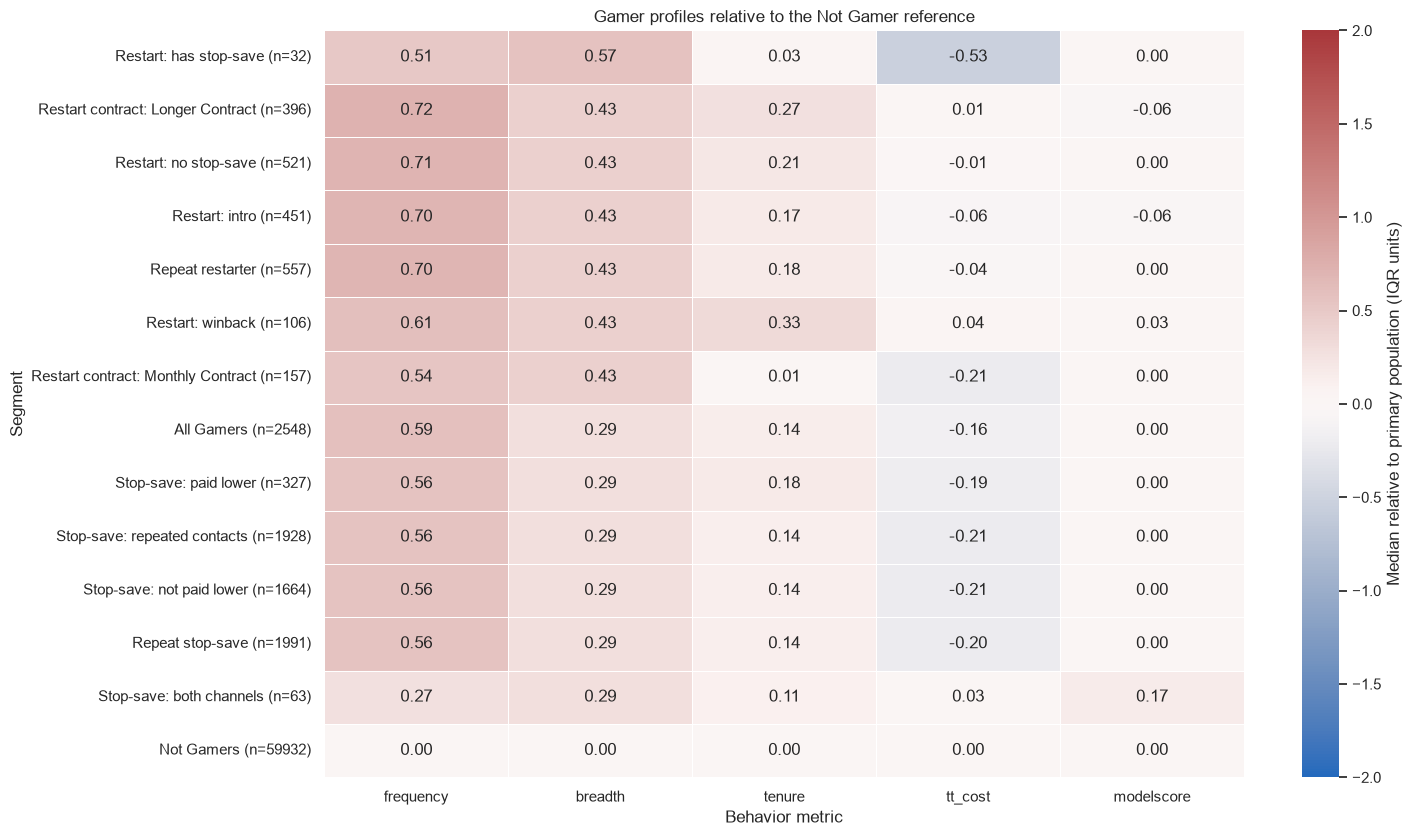

,gamer_segment,segment_label,users,median__frequency,median__breadth,median__tenure,median__tt_cost,median__modelscore,score__frequency,score__breadth,score__tenure,score__tt_cost,score__modelscore,profile_magnitude,dominant_metric
0,Restart: has stop-save,Restart: has stop-save,32,59.50,7.00,"1,358.50",237.48,6.00,0.51,0.57,0.03,-0.53,0.00,0.93,breadth
1,Restart contract: Longer Contract,Restart contract: Longer Contract,396,74.50,6.00,"1,568.00",531.80,4.00,0.72,0.43,0.27,0.01,-0.06,0.88,frequency
2,Restart: no stop-save,Restart: no stop-save,521,74.00,6.00,"1,512.00",522.29,6.00,0.71,0.43,0.21,-0.01,0.00,0.86,frequency
3,Restart: intro,Restart: intro,451,73.00,6.00,"1,482.00",493.17,4.00,0.70,0.43,0.17,-0.06,-0.06,0.84,frequency
4,Repeat restarter,Repeat restarter,557,73.00,6.00,"1,487.00",503.16,6.00,0.70,0.43,0.18,-0.04,0.00,0.84,frequency
5,Restart: winback,Restart: winback,106,66.50,6.00,"1,624.50",550.12,7.00,0.61,0.43,0.33,0.04,0.03,0.82,frequency
6,Restart contract: Monthly Contract,Restart contract: Monthly Contract,157,62.00,6.00,"1,341.00",411.92,6.00,0.54,0.43,0.01,-0.21,0.00,0.72,frequency
7,All Gamers,All Gamers,2548,65.00,5.00,"1,455.00",442.22,6.00,0.59,0.29,0.14,-0.16,0.00,0.69,frequency
8,Stop-save: paid lower,Stop-save: paid lower,327,63.00,5.00,"1,492.00",423.91,6.00,0.56,0.29,0.18,-0.19,0.00,0.68,frequency
9,Stop-save: repeated contacts,Stop-save: repeated contacts,1928,63.00,5.00,"1,453.00",412.09,6.00,0.56,0.29,0.14,-0.21,0.00,0.68,frequency


In [17]:
profile_segments = [
    ("Not Gamers", ~gamers),
    ("All Gamers", gamers),
    ("Repeat stop-save", gamers & repeat_stop_saves),
    ("Repeat restarter", gamers & repeat_restarters),
    ("Stop-save: paid lower", repeat_stop_saves & paid_lower_repeat_stop_saves),
    ("Stop-save: not paid lower", repeat_stop_saves & ~paid_lower_repeat_stop_saves),
    ("Stop-save: both channels", df["Repeat_StopSaves"].str.startswith("seek offer both channels", na=False)),
    ("Stop-save: repeated contacts", df["Repeat_StopSaves"].str.startswith("seek offer 2+", na=False)),
    ("Restart: intro", df["Repeat_Restarts"].eq("repeat restart via intro")),
    ("Restart: winback", df["Repeat_Restarts"].eq("repeat restart via winback")),
    ("Restart contract: Monthly Contract", df["service_period_type"].eq("Monthly Contract")),
    ("Restart contract: Longer Contract", df["service_period_type"].eq("Longer Contract")),
    ("Restart contract: No Payment", df["service_period_type"].eq("No Payment")),
    ("Restart: has stop-save", repeat_restarters & df["had_restart_stop_save"].eq(True)),
    ("Restart: no stop-save", repeat_restarters & df["had_restart_stop_save"].eq(False) & df["service_period_type"].ne("No Payment")),
]
gamer_profile_data = pd.concat(
    [df.loc[mask].assign(gamer_segment=label) for label, mask in profile_segments],
    ignore_index=True,
)
gamer_profiles = build_behavior_profiles(
    gamer_profile_data,
    metrics=BEHAVIOR_METRICS,
    segment_fields=["gamer_segment"],
    reference=behavior_reference,
    min_n=MIN_GAMER_PROFILE_USERS,
)
gamer_profiles.to_csv(TABLE_DIR / "gamer_behavior_profiles.csv", index=False)
_ = plot_profile_or_contrast_heatmap(
    gamer_profiles,
    metrics=BEHAVIOR_METRICS,
    score_type="profile",
    max_rows=30,
    color_limit=2.0,
    title="Gamer profiles relative to the Not Gamer reference",
    chart_folder=PROFILE_CHART_DIR,
    file_name="gamer_behavior_profiles.png",
    show=True,
)
display(gamer_profiles)

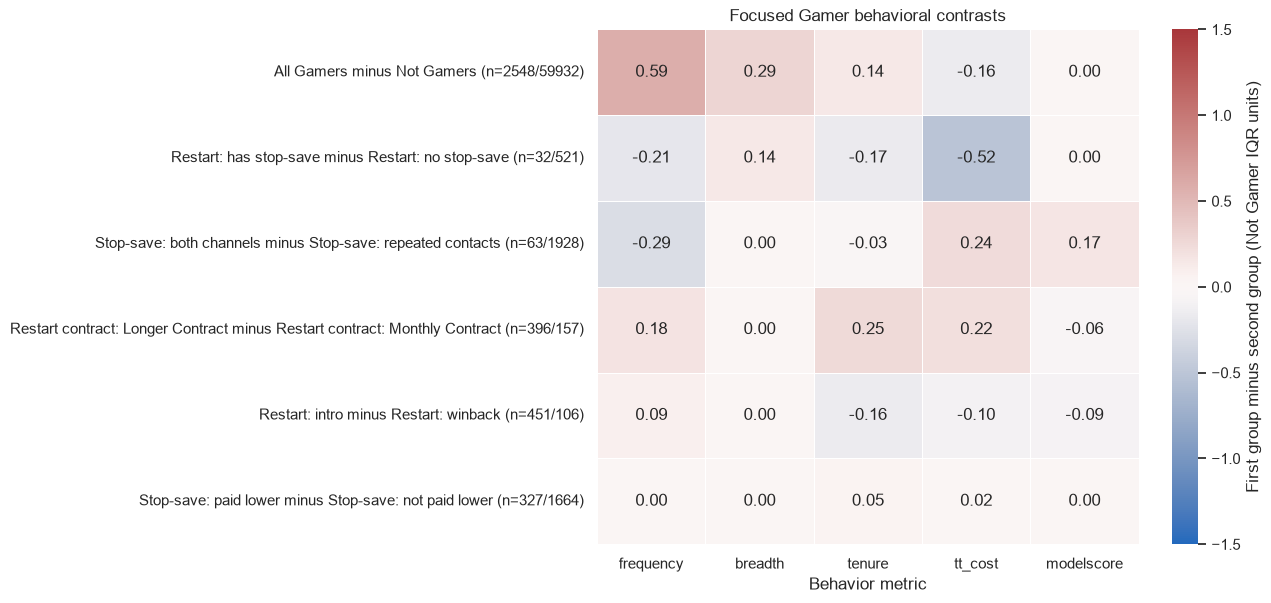

,contrast_rank,comparison,first_group,second_group,n__first,n__second,median_first__frequency,median_first__breadth,median_first__tenure,median_first__tt_cost,median_first__modelscore,median_second__frequency,median_second__breadth,median_second__tenure,median_second__tt_cost,median_second__modelscore,delta__frequency,delta__breadth,delta__tenure,delta__tt_cost,delta__modelscore,contrast_magnitude
0,0,All Gamers minus Not Gamers,All Gamers,Not Gamers,2548,59932,65.00,5.00,"1,455.00",442.22,6.00,24.00,3.00,"1,328.00",527.47,6.00,0.59,0.29,0.14,-0.16,0.00,0.69
5,1,Restart: has stop-save minus Restart: no stop-...,Restart: has stop-save,Restart: no stop-save,32,521,59.50,7.00,"1,358.50",237.48,6.00,74.00,6.00,"1,512.00",522.29,6.00,-0.21,0.14,-0.17,-0.52,0.00,0.60
2,2,Stop-save: both channels minus Stop-save: repe...,Stop-save: both channels,Stop-save: repeated contacts,63,1928,43.00,5.00,"1,424.00",544.14,12.00,63.00,5.00,"1,453.00",412.09,6.00,-0.29,0.00,-0.03,0.24,0.17,0.41
4,3,Restart contract: Longer Contract minus Restar...,Restart contract: Longer Contract,Restart contract: Monthly Contract,396,157,74.50,6.00,"1,568.00",531.80,4.00,62.00,6.00,"1,341.00",411.92,6.00,0.18,0.00,0.25,0.22,-0.06,0.38
3,4,Restart: intro minus Restart: winback,Restart: intro,Restart: winback,451,106,73.00,6.00,"1,482.00",493.17,4.00,66.50,6.00,"1,624.50",550.12,7.00,0.09,0.00,-0.16,-0.10,-0.09,0.23
1,5,Stop-save: paid lower minus Stop-save: not pai...,Stop-save: paid lower,Stop-save: not paid lower,327,1664,63.00,5.00,"1,492.00",423.91,6.00,63.00,5.00,"1,449.00",412.59,6.00,0.00,0.00,0.05,0.02,0.00,0.05


In [18]:
def build_pairwise_profile_contrasts(profiles, pairs, metrics):
    indexed = profiles.set_index("gamer_segment")
    records = []
    for first_group, second_group in pairs:
        if first_group not in indexed.index or second_group not in indexed.index:
            continue
        first = indexed.loc[first_group]
        second = indexed.loc[second_group]
        deltas = pd.Series(
            {metric: first[f"score__{metric}"] - second[f"score__{metric}"] for metric in metrics}
        )
        records.append(
            {
                "comparison": f"{first_group} minus {second_group}",
                "first_group": first_group,
                "second_group": second_group,
                "n__first": first["users"],
                "n__second": second["users"],
                **{f"median_first__{metric}": first[f"median__{metric}"] for metric in metrics},
                **{f"median_second__{metric}": second[f"median__{metric}"] for metric in metrics},
                **{f"delta__{metric}": deltas[metric] for metric in metrics},
                "contrast_magnitude": float(np.sqrt(np.square(deltas.dropna()).sum())),
            }
        )
    result = pd.DataFrame.from_records(records).sort_values("contrast_magnitude", ascending=False)
    result.insert(0, "contrast_rank", range(len(result)))
    return result

gamer_pairs = [
    ("All Gamers", "Not Gamers"),
    ("Stop-save: paid lower", "Stop-save: not paid lower"),
    ("Stop-save: both channels", "Stop-save: repeated contacts"),
    ("Restart: intro", "Restart: winback"),
    ("Restart contract: Longer Contract", "Restart contract: Monthly Contract"),
    ("Restart: has stop-save", "Restart: no stop-save"),
]
gamer_contrasts = build_pairwise_profile_contrasts(gamer_profiles, gamer_pairs, BEHAVIOR_METRICS)
gamer_contrasts.to_csv(TABLE_DIR / "gamer_pairwise_behavior_contrasts.csv", index=False)

matrix = gamer_contrasts[[f"delta__{metric}" for metric in BEHAVIOR_METRICS]].copy()
matrix.columns = BEHAVIOR_METRICS
matrix.index = [
    f"{row.comparison} (n={int(row.n__first)}/{int(row.n__second)})"
    for row in gamer_contrasts.itertuples()
]
fig, ax = plt.subplots(figsize=(13, max(5, 0.7 * len(matrix) + 2)))
sns.heatmap(
    matrix, cmap="vlag", center=0, vmin=-1.5, vmax=1.5,
    annot=True, fmt=".2f", linewidths=0.5,
    cbar_kws={"label": "First group minus second group (Not Gamer IQR units)"},
    ax=ax,
)
ax.set_title("Focused Gamer behavioral contrasts")
ax.set_xlabel("Behavior metric")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(CONTRAST_CHART_DIR / "gamer_pairwise_behavior_contrasts.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
display(gamer_contrasts)

## 6. Repeat-restarter revenue scenario

Actual paid-invoice value is compared with the P3 expected-fixed scenario by restart type, contract type, and restart stop-save status. Positive scenario difference means expected fixed revenue exceeds actual paid-invoice value. This remains a scenario calculation, not a causal estimate.

,dimension,dimension_value,restarters,actual_paid_invoice_value,expected_fixed_revenue,median_actual_paid_invoice_value,median_expected_fixed_revenue,scenario_difference,actual_to_expected_ratio
0,overall,All repeat restarters,557,47742.150000000,11121.750000000,99.00,14.99,-36620.400000000,4.29
1,restart_type,repeat restart via intro,451,40449.250000000,8374.480000000,99.00,14.99,-32074.770000000,4.83
2,restart_type,repeat restart via winback,106,7292.900000000,2747.270000000,99.00,17.48,-4545.630000000,2.65
3,restart_contract_type,Longer Contract,396,44737.000000000,5886.020000000,119.00,14.99,-38850.980000000,7.60
4,restart_contract_type,Monthly Contract,157,3005.150000000,5235.730000000,15.99,29.98,2230.580000000,0.57
5,restart_contract_type,No Payment,4,0E-9,0E-9,0.00,0.00,0E-9,NaN
6,restart_stop_save,False,525,47337.870000000,10050.270000000,99.00,14.99,-37287.600000000,4.71
7,restart_stop_save,True,32,404.280000000,1071.480000000,10.98,27.96,667.200000000,0.38


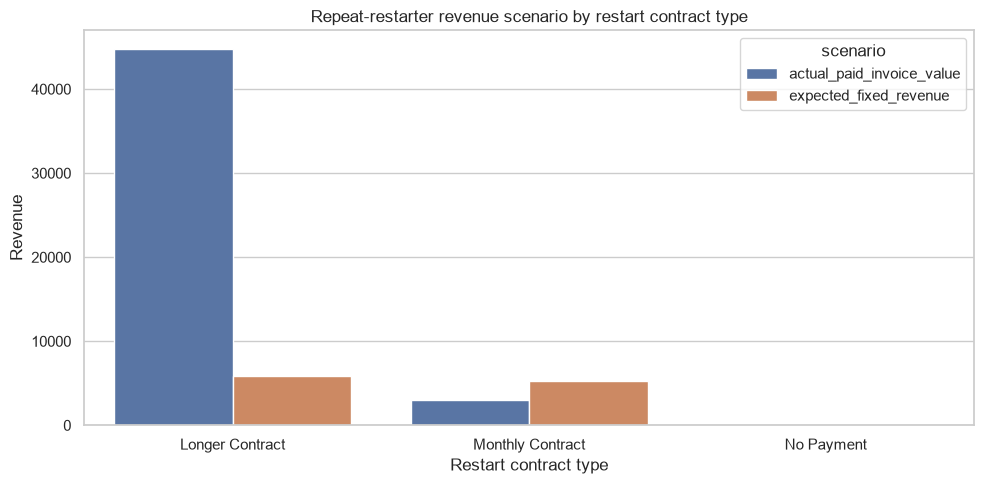

In [19]:
def summarize_restart_revenue(data, dimension, dimension_label):
    grouped = (
        data.groupby(dimension, dropna=False)
        .agg(
            restarters=("id_subscrip", "nunique"),
            actual_paid_invoice_value=("actual_paid_invoice_value", "sum"),
            expected_fixed_revenue=("expected_fixed_revenue", "sum"),
            median_actual_paid_invoice_value=("actual_paid_invoice_value", "median"),
            median_expected_fixed_revenue=("expected_fixed_revenue", "median"),
        )
        .reset_index()
        .rename(columns={dimension: "dimension_value"})
    )
    grouped.insert(0, "dimension", dimension_label)
    grouped["scenario_difference"] = (
        grouped["expected_fixed_revenue"] - grouped["actual_paid_invoice_value"]
    )
    grouped["actual_to_expected_ratio"] = np.nan
    nonzero_expected = grouped["expected_fixed_revenue"].ne(0)
    grouped.loc[nonzero_expected, "actual_to_expected_ratio"] = (
        grouped.loc[nonzero_expected, "actual_paid_invoice_value"].astype(float)
        / grouped.loc[nonzero_expected, "expected_fixed_revenue"].astype(float)
    )
    return grouped

restarters = df.loc[repeat_restarters].copy()
restarters["overall"] = "All repeat restarters"
revenue_summary = pd.concat(
    [
        summarize_restart_revenue(restarters, "overall", "overall"),
        summarize_restart_revenue(restarters, "Repeat_Restarts", "restart_type"),
        summarize_restart_revenue(restarters, "service_period_type", "restart_contract_type"),
        summarize_restart_revenue(restarters, "had_restart_stop_save", "restart_stop_save"),
    ],
    ignore_index=True,
)
revenue_summary.to_csv(TABLE_DIR / "repeat_restarter_revenue_summary.csv", index=False)
display(revenue_summary)

contract_revenue = revenue_summary[revenue_summary["dimension"].eq("restart_contract_type")].copy()
contract_plot = contract_revenue.melt(
    id_vars="dimension_value",
    value_vars=["actual_paid_invoice_value", "expected_fixed_revenue"],
    var_name="scenario",
    value_name="revenue",
)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=contract_plot, x="dimension_value", y="revenue", hue="scenario", ax=ax)
ax.set_title("Repeat-restarter revenue scenario by restart contract type")
ax.set_xlabel("Restart contract type")
ax.set_ylabel("Revenue")
fig.tight_layout()
fig.savefig(REVENUE_CHART_DIR / "revenue_by_restart_contract_type.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## 7. Interpretation boundaries

- The Not Gamer reference is the common scale for all behavioral profiles.
- Main Saved-versus-Stopped contrasts use voluntary stops only.
- No Action and involuntary-stop users are population context, not the primary behavioral comparison.
- Gamer subgroups overlap and should not be summed.
- Categorical share differences and treatment drill-downs are descriptive.
- Revenue differences represent the stated fixed-rate scenario and do not estimate causal lift.